# Lab 11: Attention


### Attention is a mechanism that allows a neural network to focus more on relevant information when making a prediction.

Encoder-decoder architecture with attention:
<img src="https://drive.google.com/thumbnail?id=1-QeHdZIeKTo_nAqfh7pRA_o4Nk8CAmP6&sz=w1000" width="700">

## Step 1 — Import libraries

In [1]:
import pandas as pd
import torch
from torch import nn
import matplotlib.pyplot as plt

torch.manual_seed(42)

## Step 2 — Upload the dataset

In [3]:
df = pd.read_csv("/Users/marialsha1/Desktop/Uni/NLP_Lab11/dataset/Lab_11_QnA_Dataset.csv")
print("Number of questions:", len(df))
print("Number of answer groups:", df["answer_id"].nunique())
display(df.head())

Number of questions: 168
Number of answer groups: 12


,question,answer_id,answer
0,Do you get hurt?,0,I don't have a body.
1,Do you have fingers?,0,I don't have a body.
2,Do you ever breathe,0,I don't have a body.
3,Do you masticate?,0,I don't have a body.
4,Can you throw up?,0,I don't have a body.


## Step 3 — Preprocessing

1. Lowercase each question and remove punctuation.
2. Give each word a number.
3. Make all questions the same length by adding zeros (**padding**).

In [4]:
from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences

# 1. Lowercase
df["question"] = df["question"].str.lower()

# 2. Tokenization
tokenizer = Tokenizer()
tokenizer.fit_on_texts(df["question"])

# Convert words to numbers and add padding
X = pad_sequences(tokenizer.texts_to_sequences(df["question"]), padding="post")

# Answers
y = df["answer_id"].values

# Convert to PyTorch tensors
X = torch.tensor(X, dtype=torch.long)
y = torch.tensor(y, dtype=torch.long)

## Step 4 — Build an RNN with attention

- **Embedding** turns word numbers into vectors.
- **RNN** reads the words in sequence.
- **Attention** gives each word a weight.
- **Output** chooses one answer from the dataset.

In [5]:
y = torch.tensor(pd.factorize(df["answer_id"])[0], dtype=torch.long)
class RNN(nn.Module):
    def __init__(self):
        super().__init__()
        self.emb = nn.Embedding(len(tokenizer.word_index) + 1, 16)
        self.rnn = nn.RNN(16, 32, batch_first=True)
        self.att = nn.Linear(32, 1)
        self.fc = nn.Linear(32, df["answer_id"].nunique())

    def forward(self, x):
        mask = x != 0
        x, _ = self.rnn(self.emb(x))
        scores = self.att(x).squeeze(-1)
        scores = scores.masked_fill(~mask, float("-inf"))
        weights = torch.softmax(scores, dim=1)
        return self.fc((x * weights.unsqueeze(-1)).sum(1)), weights

model = RNN()

## Step 5 — Train the model
The model learns which answer belongs to each question.

In [6]:
optimizer = torch.optim.Adam(model.parameters(), lr=0.01)
model.train()

for epoch in range(50):
    optimizer.zero_grad()
    loss = nn.functional.cross_entropy(model(X)[0], y)
    loss.backward()
    optimizer.step()

model.eval()
print("Training finished!")

Training finished!


## Step 6 — See attention
The bar chart shows how much attention the model gives to each question word.

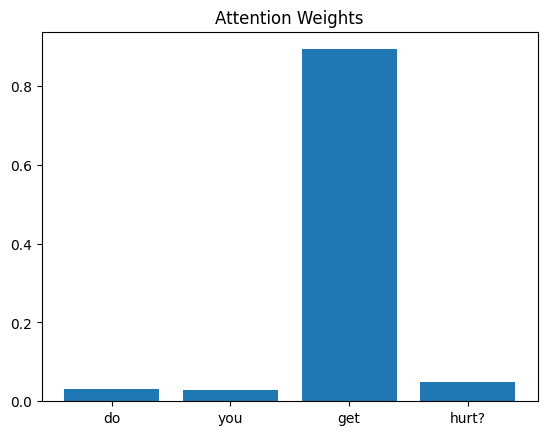

In [11]:
question = df["question"][0]
words = question.split()

with torch.no_grad():
    prediction, weights = model(X[:1])

plt.bar(words, weights[0, :len(words)].tolist())
plt.title("Attention Weights")
plt.show()

## Tasks:


Task 1 — Understand Attention Weights
Easy

Modify Step 6 to visualize the attention weights for three different questions from the dataset instead of only the first question.

Instructions:
- Select three questions from the dataset.
- Generate an attention bar chart for each question.
- Identify the word receiving the highest attention weight in each question.

Question: Do the words with the highest attention weights appear important for understanding the question? Explain your observations.

Question: do you get hurt?
Highest attention word: get
Attention weight: 0.8931


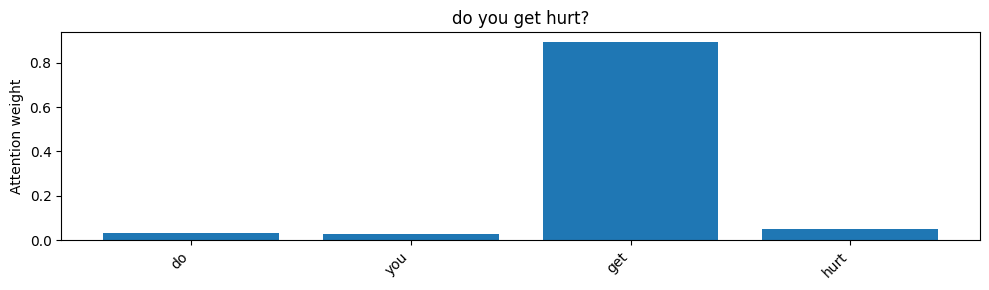

Question: do you have fingers?
Highest attention word: fingers
Attention weight: 0.529


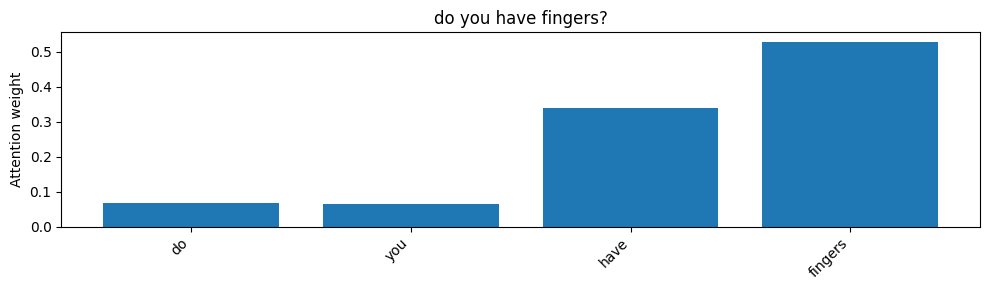

Question: do you ever breathe
Highest attention word: breathe
Attention weight: 0.6909


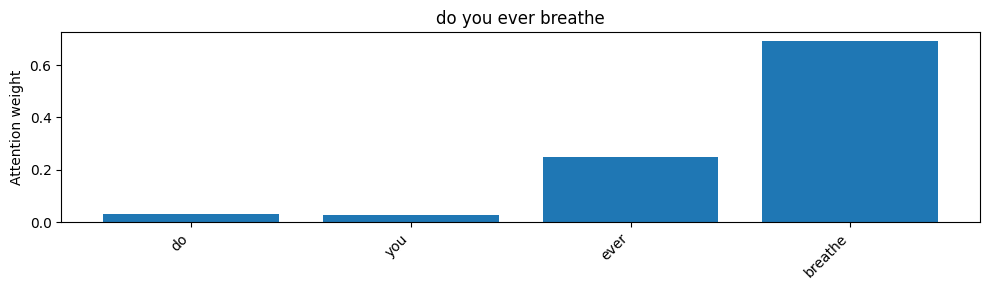

In [12]:
indices = df.drop_duplicates("question").index[:3]

for i in indices:
    question = df.loc[i, "question"]
    tokens = X[i][X[i] != 0].tolist()
    words = [tokenizer.index_word[token] for token in tokens]

    with torch.no_grad():
        prediction, weights = model(X[i:i + 1])

    attention = weights[0, :len(words)]
    highest = attention.argmax().item()

    print("Question:", question)
    print("Highest attention word:", words[highest])
    print("Attention weight:", round(attention[highest].item(), 4))

    plt.figure(figsize=(10, 3))
    plt.bar(range(len(words)), attention.tolist())
    plt.xticks(range(len(words)), words, rotation=45, ha="right")
    plt.title(question)
    plt.ylabel("Attention weight")
    plt.tight_layout()
    plt.show()

The highest-attention words appear important in two of the three questions. “Fingers” and “breathe” express the main topics of their questions. However, in “Do you get hurt?”, the model focuses on “get”, although “hurt” is more meaningful for understanding the question. This shows that attention can highlight relevant words, but it does not always match what humans consider most important.

Task 2 — Compare Attention for Similar Questions
Medium

Select two questions from the dataset that have similar meanings but different wording.

Instructions:
- Pass both questions through the trained model.
- Visualize their attention weights.
- Compare the words receiving the highest attention weights.

Question: Does the model focus on similar or different words when processing questions with similar meanings? What does this suggest about how attention works?

Question: do you get hurt?
Highest attention word: get
Attention weight: 0.8931


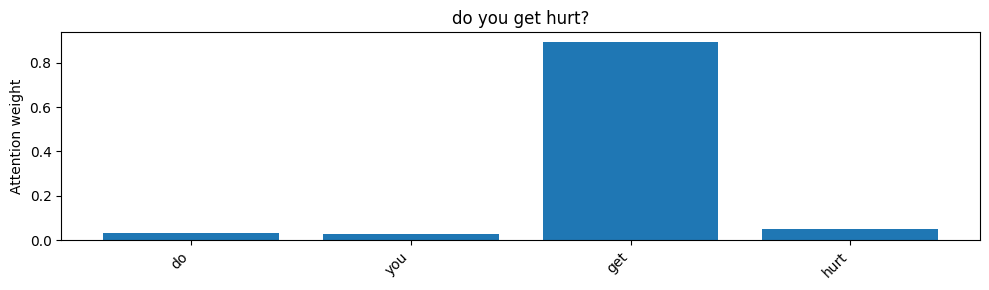

Question: do you have fingers?
Highest attention word: fingers
Attention weight: 0.529


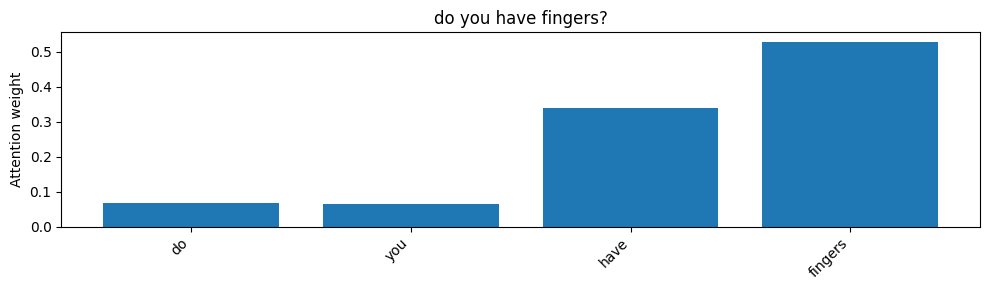

The model focuses on different words: get and fingers
These words may express related ideas. Attention depends on wording and context, so similar questions can have different attention patterns.


In [13]:
indices = []

for answer_id, group in df.groupby("answer_id", sort=False):
    group = group.drop_duplicates("question")
    if len(group) >= 2:
        indices = group.index[:2].tolist()
        break

if len(indices) < 2:
    raise ValueError("No two different questions share an answer label.")

highest_words = []

for i in indices:
    question = df.loc[i, "question"]
    tokens = X[i][X[i] != 0].tolist()
    words = [tokenizer.index_word[token] for token in tokens]

    with torch.no_grad():
        prediction, weights = model(X[i:i + 1])

    attention = weights[0, :len(words)]
    highest = attention.argmax().item()
    highest_words.append(words[highest])

    print("Question:", question)
    print("Highest attention word:", words[highest])
    print("Attention weight:", round(attention[highest].item(), 4))

    plt.figure(figsize=(10, 3))
    plt.bar(range(len(words)), attention.tolist())
    plt.xticks(range(len(words)), words, rotation=45, ha="right")
    plt.title(question)
    plt.ylabel("Attention weight")
    plt.tight_layout()
    plt.show()

if highest_words[0] == highest_words[1]:
    print("The model focuses on the same word in both questions:", highest_words[0])
    print("This suggests that the model uses a shared word as a cue despite different wording.")
else:
    print("The model focuses on different words:", highest_words[0], "and", highest_words[1])
    print("These words may express related ideas. Attention depends on wording and context, so similar questions can have different attention patterns.")